/tmp/ipykernel_2533/4202071170.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Category', y='Sales', data=df, estimator=sum, errorbar=None, palette='viridis')


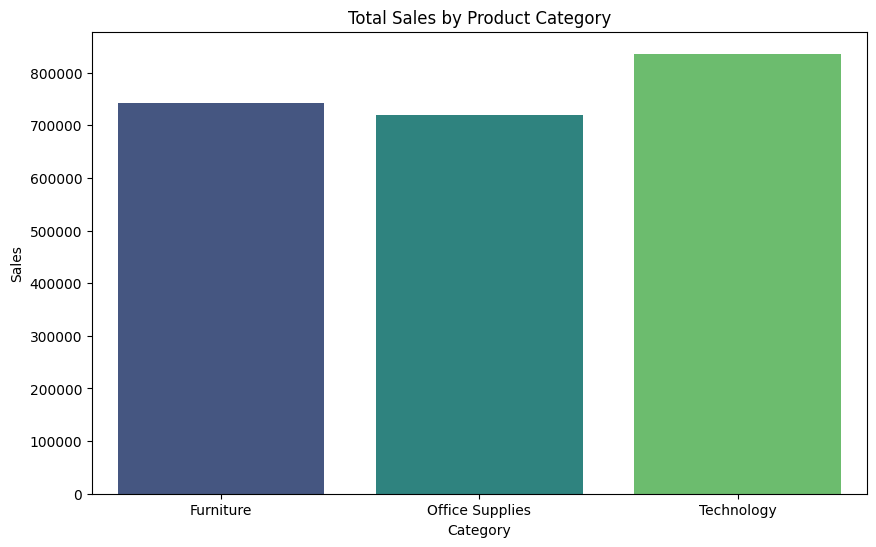

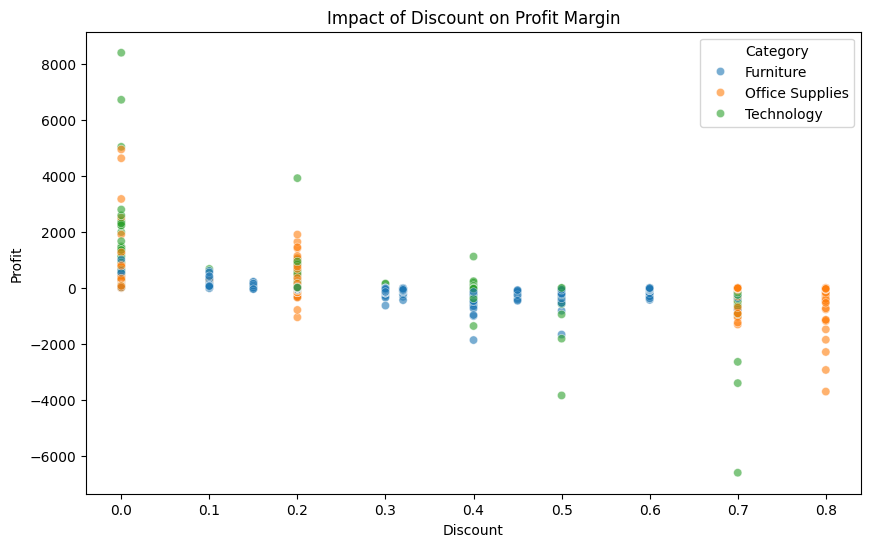

Model Mean Squared Error: 61717.64
Model R-squared Score: -0.27


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Load and clean the dataset
df = pd.read_csv("SampleSuperstore.csv", encoding='windows-1252')
df.drop_duplicates(inplace=True)
df = df.drop(['Country', 'Postal Code'], axis=1, errors='ignore')

# 2. Exploratory Data Analysis (EDA)
plt.figure(figsize=(10, 6))
sns.barplot(x='Category', y='Sales', data=df, estimator=sum, errorbar=None, palette='viridis')
plt.title('Total Sales by Product Category')
plt.show()

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Discount', y='Profit', data=df, hue='Category', alpha=0.6)
plt.title('Impact of Discount on Profit Margin')
plt.show()

# 3. Machine Learning Model (Predicting Profit)
features = ['Sales', 'Quantity', 'Discount']
X = df[features]
y = df['Profit']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

predictions = model.predict(X_test)
print(f"Model Mean Squared Error: {mean_squared_error(y_test, predictions):.2f}")
print(f"Model R-squared Score: {r2_score(y_test, predictions):.2f}")